# Strategy Comparison for Grover Search with Unknown Numbers of Solutions

## Research question

The previous notebook established that adaptive BBHT can discover a useful Grover iteration scale without knowing the number of marked states $s$ in advance.

The next question is

$$
\boxed{
\text{How does adaptive BBHT compare with other strategies for handling uncertainty in }s
\text{ on finite instances?}
}
$$

This notebook is designed as a finite instance comparison rather than a new asymptotic complexity proof.

The comparison will focus on

1. expected oracle query cost,
2. runtime distribution and tail behavior,
3. robustness to uncertainty,
4. prior information requirements,
5. implementation complexity.

The notebook will not assume in advance that one strategy is best.

## 1. Comparison philosophy

Different methods handle uncertainty in $s$ in fundamentally different ways.

Adaptive BBHT does not estimate $s$. It increases the randomized Grover range until a useful scale is reached.

Quantum counting instead attempts to infer information about the number of marked states before that information is used for search.

Optimal fixed point search changes the amplification sequence so that success can remain high over a prescribed range of initial target fractions rather than depending on one precise Grover stopping point.

These approaches do not receive identical prior information.

Therefore a fair finite comparison must report not only query cost, but also what each strategy is allowed to know.

## 2. Strategy map and information assumptions

The final comparison will use the following roles.

| Strategy | Information available before search | Role in Notebook 05 |
| --- | --- | --- |
| Known $s$ restart | Exact $s$ | Oracle informed reference |
| Classical uniform sampling | No knowledge of $s$ | Classical reference |
| Adaptive BBHT | $N$, but not $s$ | Main unknown $s$ strategy |
| Counting assisted search | $N$, but not $s$; an estimation budget is chosen | Estimate then search strategy |
| Optimal fixed point search | A reliable lower bound on the target fraction and a target failure tolerance | Robust prior informed strategy |

The known $s$ strategy is not an equal information competitor. It provides a reference for the finite cost of having perfect information.

Classical sampling is included because the comparison should show whether additional quantum machinery produces a useful finite advantage rather than only an asymptotic one.

## 3. Fair comparison contract

Before implementing the remaining strategies, the cost model is fixed.

### 3.1 Common search problem

For every instance,

$$
N=|X|,
\qquad
1\le s<N,
$$

and exactly $s$ elements are marked by the same abstract Boolean oracle.

A successful run must return a marked element.

### 3.2 Primary query metric

The primary metric will be complete oracle queries required to obtain and verify a marked output.

For adaptive BBHT this is the same phase oracle metric used in Notebook 04:

$$
Q_{\mathrm{phase}}
=
\sum_r j_r + R,
$$

where $j_r$ is the number of Grover iterations in round $r$ and $R$ is the number of verification rounds.

For a known $s$ restart strategy using $t$ Grover iterations per attempt,

$$
C_{\mathrm{phase}}(t)
=
\frac{t+1}{P(t)}.
$$

For classical uniform sampling, one candidate check is one oracle query.

For counting assisted search, every oracle evaluation used during estimation must be added to the later search and verification cost.

For fixed point search, every target oracle application in the amplification sequence must be counted. If the final candidate is explicitly verified, that verification must also be counted.

### 3.3 Secondary metrics

Where the oracle model permits it, the BBHT style table lookup metric from Notebook 04 may also be reported.

The main cross strategy comparison will not mix Grover iterations, oracle calls, and table lookups as though they were interchangeable resources.

### 3.4 Distributional comparison

Expected cost alone is not sufficient.

For stochastic complete search procedures we will report at least

$$
\mathbb E[Q],
\qquad
\operatorname{median}(Q),
\qquad
Q_{0.90},
\qquad
Q_{0.95},
$$

and, where useful,

$$
\frac{Q_{0.95}}{\mathbb E[Q]}.
$$

## 4. Source grounded expectations before experimentation

This section records what the reference algorithms imply before finite benchmarking.

Boyer, Brassard, Høyer, and Tapp prove that adaptive randomized search finds a marked element in expected

$$
O\!\left(\sqrt{\frac Ns}\right)
$$

time for the principal regime $1\le s\le 3N/4$.

Their procedure starts with a small randomization range, chooses a random Grover iteration count inside that range, verifies the candidate, and increases the range geometrically after failure.

Quantum counting treats the number of marked states as an estimation problem. Its precision depends on a chosen parameter $P$, and the counting procedure itself consumes oracle evaluations. Any estimate then search comparison must therefore charge the estimation stage rather than treating the estimate as free.

The optimal fixed point construction of Yoder, Low, and Chuang avoids the usual overshooting behavior while retaining quadratic scaling. Its guarantee is parameterized by prior information about the target fraction and by a chosen failure tolerance.

These statements give expectations to test. They do not determine which method has the best finite cost under different information assumptions.

## 5. Common mathematical helpers

In [1]:
from math import asin, sqrt, sin, ceil, log

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

NumPy version: 2.4.2
Pandas version: 3.0.0


In [2]:
def validate_search_instance(N, s):
    if not isinstance(N, (int, np.integer)) or N < 2:
        raise ValueError("N must be an integer with N >= 2")

    if not isinstance(s, (int, np.integer)):
        raise ValueError("s must be an integer")

    if not 1 <= s < N:
        raise ValueError("s must satisfy 1 <= s < N")

    return int(N), int(s)


def validate_iteration_count(t):
    if not isinstance(t, (int, np.integer)) or t < 0:
        raise ValueError("t must be a nonnegative integer")

    return int(t)


def theta_from_N_s(N, s):
    N, s = validate_search_instance(N, s)
    return asin(sqrt(s / N))


def grover_probability(N, s, t):
    t = validate_iteration_count(t)
    theta = theta_from_N_s(N, s)

    return float(
        sin((2 * t + 1) * theta) ** 2
    )


def geometric_attempt_quantile(success_probability, quantile):
    if not 0 < success_probability <= 1:
        raise ValueError("success_probability must lie in (0, 1]")

    if not 0 < quantile < 1:
        raise ValueError("quantile must lie in (0, 1)")

    if success_probability == 1:
        return 1

    return int(
        ceil(
            log(1 - quantile)
            / log(1 - success_probability)
        )
    )


print("Common helper definitions: PASS")

Common helper definitions: PASS


## 6. Oracle informed reference: known $s$ restart

The known $s$ reference is inherited from Notebook 04.

For a fixed integer stopping time $t$,

$$
P(t)
=
\sin^2((2t+1)\theta).
$$

If the measured candidate is verified and the procedure restarts after failure, the expected complete phase oracle cost is

$$
C_{\mathrm{phase}}(t)
=
\frac{t+1}{P(t)}.
$$

The benchmark searches over integer $t$ and stops only when lower bounds on every later candidate cost prove that no later $t$ can improve the best value already found.

This is an oracle informed reference because it uses the true value of $s$ when choosing $t$.

In [3]:
def known_s_restart_benchmark(N, s):
    N, s = validate_search_instance(N, s)

    best_phase_cost = float("inf")
    best_t = None
    best_probability = None

    t = 0

    while True:
        p = grover_probability(N, s, t)
        phase_cost = (t + 1) / p

        if phase_cost < best_phase_cost:
            best_phase_cost = phase_cost
            best_t = t
            best_probability = p

        next_t = t + 1

        # Since P(t) <= 1, every later complete phase cost
        # is at least next_t + 1.
        if next_t + 1 > best_phase_cost:
            break

        t = next_t

    q50_attempts = geometric_attempt_quantile(
        best_probability,
        0.50,
    )

    q90_attempts = geometric_attempt_quantile(
        best_probability,
        0.90,
    )

    q95_attempts = geometric_attempt_quantile(
        best_probability,
        0.95,
    )

    attempt_cost = best_t + 1

    return {
        "N": N,
        "s": s,
        "optimal_t": int(best_t),
        "attempt_success_probability":
            float(best_probability),
        "mean_phase_queries":
            float(best_phase_cost),
        "median_phase_queries":
            float(q50_attempts * attempt_cost),
        "q90_phase_queries":
            float(q90_attempts * attempt_cost),
        "q95_phase_queries":
            float(q95_attempts * attempt_cost),
    }


known_s_sanity = pd.DataFrame([
    known_s_restart_benchmark(256, s)
    for s in [1, 2, 4, 8, 16]
])

known_s_sanity

,N,s,optimal_t,attempt_success_probability,mean_phase_queries,median_phase_queries,q90_phase_queries,q95_phase_queries
0,256,1,9,0.860676,11.618773,10.0,20.0,20.0
1,256,2,6,0.833548,8.397838,7.0,14.0,14.0
2,256,4,4,0.816377,6.124621,5.0,10.0,10.0
3,256,8,3,0.896937,4.459624,4.0,8.0,8.0
4,256,16,2,0.908447,3.302338,3.0,3.0,6.0


## 7. Classical reference: uniform sampling

A classical reference repeatedly samples a candidate uniformly and queries the oracle.

Each query succeeds with probability

$$
a=\frac{s}{N}.
$$

The complete query count is therefore geometrically distributed.

Its mean is exactly

$$
\mathbb E[Q_{\mathrm{classical}}]
=
\frac Ns.
$$

This reference requires no prior knowledge of $s$ to run. The value of $s$ is used only afterward to calculate the exact distribution for analysis.

In [4]:
def classical_uniform_sampling_benchmark(N, s):
    N, s = validate_search_instance(N, s)

    p = s / N

    q50 = geometric_attempt_quantile(p, 0.50)
    q90 = geometric_attempt_quantile(p, 0.90)
    q95 = geometric_attempt_quantile(p, 0.95)

    return {
        "N": N,
        "s": s,
        "single_query_success_probability": p,
        "mean_queries": float(1 / p),
        "median_queries": float(q50),
        "q90_queries": float(q90),
        "q95_queries": float(q95),
    }


classical_sanity = pd.DataFrame([
    classical_uniform_sampling_benchmark(
        256,
        s,
    )
    for s in [1, 2, 4, 8, 16]
])

classical_sanity

,N,s,single_query_success_probability,mean_queries,median_queries,q90_queries,q95_queries
0,256,1,0.003906,256.0,178.0,589.0,766.0
1,256,2,0.007812,128.0,89.0,294.0,382.0
2,256,4,0.015625,64.0,45.0,147.0,191.0
3,256,8,0.031250,32.0,22.0,73.0,95.0
4,256,16,0.062500,16.0,11.0,36.0,47.0


## 8. Adaptive BBHT bridge from Notebook 04

Before comparing BBHT with new strategies, Notebook 05 should reproduce the Notebook 04 implementation exactly enough that the same seeds give the same finite results.

The real valued range convention is retained.

For a current range $m>0$, the allowed integer Grover counts are exactly

$$
j\in
\{0,\ldots,\lceil m\rceil-1\}.
$$

The growth factor must satisfy

$$
1<\lambda<\frac43.
$$

The principal BBHT experiment remains restricted to

$$
1\le s\le\frac{3N}{4}.
$$

In [5]:
def run_adaptive_bbht(
    N,
    s,
    growth=6/5,
    seed=None,
    max_rounds=100000,
):
    N, s = validate_search_instance(N, s)

    if not 1 < growth < 4/3:
        raise ValueError(
            "growth must satisfy 1 < growth < 4/3"
        )

    if not 1 <= s <= 3 * N / 4:
        raise ValueError(
            "Main adaptive BBHT experiments require "
            "1 <= s <= 3N/4"
        )

    rng = np.random.default_rng(seed)

    m = 1.0
    sqrt_N = sqrt(N)

    total_grover_iterations = 0
    rounds = 0

    while rounds < max_rounds:
        rounds += 1

        m_integer = max(
            1,
            int(ceil(m)),
        )

        j = int(
            rng.integers(
                0,
                m_integer,
            )
        )

        p_success = grover_probability(
            N,
            s,
            j,
        )

        success = bool(
            rng.random() < p_success
        )

        total_grover_iterations += j

        if success:
            return {
                "N": N,
                "s": s,
                "growth": growth,
                "rounds": rounds,
                "grover_iterations":
                    total_grover_iterations,
                "phase_oracle_queries":
                    total_grover_iterations + rounds,
                "table_lookup_queries":
                    2 * total_grover_iterations + rounds,
            }

        m = min(
            growth * m,
            sqrt_N,
        )

    raise RuntimeError(
        "Maximum number of rounds reached"
    )


def simulate_adaptive_bbht(
    N,
    s,
    growth=6/5,
    runs=3000,
    base_seed=1000,
):
    records = []

    for r in range(runs):
        result = run_adaptive_bbht(
            N=N,
            s=s,
            growth=growth,
            seed=base_seed + r,
        )

        records.append(result)

    df = pd.DataFrame(records)

    phase = df["phase_oracle_queries"]

    return {
        "N": int(N),
        "s": int(s),
        "growth": float(growth),
        "runs": int(runs),
        "mean_phase_queries":
            float(phase.mean()),
        "median_phase_queries":
            float(phase.median()),
        "q90_phase_queries":
            float(phase.quantile(0.90)),
        "q95_phase_queries":
            float(phase.quantile(0.95)),
        "tail_overhead_q95_over_mean":
            float(
                phase.quantile(0.95)
                / phase.mean()
            ),
        "mean_grover_iterations":
            float(
                df["grover_iterations"].mean()
            ),
        "mean_rounds":
            float(df["rounds"].mean()),
    }, df


print("Adaptive BBHT definitions: PASS")

Adaptive BBHT definitions: PASS


### 8.1 Reproduce the fixed $N$ results from Notebook 04

The following check uses the same

$$
N=1024,
\qquad
\lambda=\frac65,
\qquad
3000
$$

runs and the same deterministic seed rule as Notebook 04.

The purpose is not to create a new result.

It is a bridge check showing that Notebook 05 begins from the same BBHT implementation and finite data before introducing new comparison strategies.

In [6]:
N_bridge = 1024
s_bridge = [1, 2, 4, 8, 16, 32, 64]

notebook04_phase_means = {
    1: 51.63166666666667,
    2: 36.922666666666665,
    4: 26.399,
    8: 18.439333333333334,
    16: 12.836333333333334,
    32: 8.773,
    64: 5.730666666666667,
}

bridge_rows = []
bbht_samples = {}

for s in s_bridge:
    summary, samples = simulate_adaptive_bbht(
        N=N_bridge,
        s=s,
        growth=6/5,
        runs=3000,
        base_seed=10_000 + s,
    )

    bbht_samples[(N_bridge, s)] = samples

    reference = notebook04_phase_means[s]
    discrepancy = (
        summary["mean_phase_queries"]
        - reference
    )

    bridge_rows.append({
        "N": N_bridge,
        "s": s,
        "Notebook_04_mean_Q_phase":
            reference,
        "Notebook_05_mean_Q_phase":
            summary["mean_phase_queries"],
        "discrepancy":
            discrepancy,
        "matches_to_1e_12":
            abs(discrepancy) <= 1e-12,
    })

bridge_df = pd.DataFrame(bridge_rows)
bridge_df

,N,s,Notebook_04_mean_Q_phase,Notebook_05_mean_Q_phase,discrepancy,matches_to_1e_12
0,1024,1,51.631667,51.631667,0.0,True
1,1024,2,36.922667,36.922667,0.0,True
2,1024,4,26.399000,26.399000,0.0,True
3,1024,8,18.439333,18.439333,0.0,True
4,1024,16,12.836333,12.836333,0.0,True
5,1024,32,8.773000,8.773000,0.0,True
6,1024,64,5.730667,5.730667,0.0,True


In [7]:
bridge_pass = bool(
    bridge_df[
        "matches_to_1e_12"
    ].all()
)

print(
    "Notebook 04 to Notebook 05 BBHT bridge:",
    "PASS" if bridge_pass else "CHECK",
)

print(
    "Maximum absolute mean discrepancy:",
    float(
        bridge_df[
            "discrepancy"
        ].abs().max()
    ),
)

Notebook 04 to Notebook 05 BBHT bridge: PASS
Maximum absolute mean discrepancy: 0.0


## 9. First finite comparison: references and adaptive BBHT

This first table is deliberately limited.

It compares adaptive BBHT with the two reference strategies already defined:

1. perfect knowledge of $s$,
2. no quantum amplification at all.

Quantum counting assisted search and optimal fixed point search have not yet been inserted, so this table must not be interpreted as the final strategy ranking.

The purpose is to establish the numerical scale against which those new strategies will later be judged.

In [8]:
comparison_rows = []

for s in s_bridge:
    known = known_s_restart_benchmark(
        N_bridge,
        s,
    )

    classical = (
        classical_uniform_sampling_benchmark(
            N_bridge,
            s,
        )
    )

    bbht_summary, bbht_df = (
        simulate_adaptive_bbht(
            N=N_bridge,
            s=s,
            growth=6/5,
            runs=3000,
            base_seed=10_000 + s,
        )
    )

    comparison_rows.append({
        "N": N_bridge,
        "s": s,
        "sqrt_N_over_s":
            sqrt(N_bridge / s),

        "known_s_mean_Q":
            known["mean_phase_queries"],
        "known_s_q95_Q":
            known["q95_phase_queries"],

        "BBHT_mean_Q":
            bbht_summary[
                "mean_phase_queries"
            ],
        "BBHT_q95_Q":
            bbht_summary[
                "q95_phase_queries"
            ],

        "classical_mean_Q":
            classical["mean_queries"],
        "classical_q95_Q":
            classical["q95_queries"],

        "BBHT_over_known_mean":
            (
                bbht_summary[
                    "mean_phase_queries"
                ]
                / known[
                    "mean_phase_queries"
                ]
            ),

        "classical_over_BBHT_mean":
            (
                classical[
                    "mean_queries"
                ]
                / bbht_summary[
                    "mean_phase_queries"
                ]
            ),
    })

baseline_comparison_df = pd.DataFrame(
    comparison_rows
)

baseline_comparison_df

,N,s,sqrt_N_over_s,known_s_mean_Q,known_s_q95_Q,BBHT_mean_Q,BBHT_q95_Q,classical_mean_Q,classical_q95_Q,BBHT_over_known_mean,classical_over_BBHT_mean
0,1024,1,32.000000,22.675431,38.0,51.631667,96.0,1024.0,3067.0,2.276987,19.832790
1,1024,2,22.627417,16.196855,28.0,36.922667,71.0,512.0,1533.0,2.279620,13.866821
2,1024,4,16.000000,11.618773,20.0,26.399000,50.0,256.0,766.0,2.272099,9.697337
3,1024,8,11.313708,8.397838,14.0,18.439333,35.0,128.0,382.0,2.195724,6.941683
4,1024,16,8.000000,6.124621,10.0,12.836333,25.0,64.0,191.0,2.095858,4.985847
5,1024,32,5.656854,4.459624,8.0,8.773000,18.0,32.0,95.0,1.967206,3.647555
6,1024,64,4.000000,3.302338,6.0,5.730667,12.0,16.0,47.0,1.735336,2.791996


In [9]:
baseline_tail_df = baseline_comparison_df[
    [
        "s",
        "known_s_mean_Q",
        "known_s_q95_Q",
        "BBHT_mean_Q",
        "BBHT_q95_Q",
        "classical_mean_Q",
        "classical_q95_Q",
    ]
].copy()

baseline_tail_df[
    "known_q95_over_mean"
] = (
    baseline_tail_df["known_s_q95_Q"]
    / baseline_tail_df["known_s_mean_Q"]
)

baseline_tail_df[
    "BBHT_q95_over_mean"
] = (
    baseline_tail_df["BBHT_q95_Q"]
    / baseline_tail_df["BBHT_mean_Q"]
)

baseline_tail_df[
    "classical_q95_over_mean"
] = (
    baseline_tail_df["classical_q95_Q"]
    / baseline_tail_df["classical_mean_Q"]
)

baseline_tail_df[
    "BBHT_over_known_q95"
] = (
    baseline_tail_df["BBHT_q95_Q"]
    / baseline_tail_df["known_s_q95_Q"]
)

baseline_tail_df[
    "classical_over_BBHT_q95"
] = (
    baseline_tail_df["classical_q95_Q"]
    / baseline_tail_df["BBHT_q95_Q"]
)

baseline_tail_df

,s,known_s_mean_Q,known_s_q95_Q,BBHT_mean_Q,BBHT_q95_Q,classical_mean_Q,classical_q95_Q,known_q95_over_mean,BBHT_q95_over_mean,classical_q95_over_mean,BBHT_over_known_q95,classical_over_BBHT_q95
0,1,22.675431,38.0,51.631667,96.0,1024.0,3067.0,1.675823,1.859324,2.995117,2.526316,31.947917
1,2,16.196855,28.0,36.922667,71.0,512.0,1533.0,1.728731,1.922938,2.994141,2.535714,21.591549
2,4,11.618773,20.0,26.399000,50.0,256.0,766.0,1.721352,1.894011,2.992188,2.500000,15.320000
3,8,8.397838,14.0,18.439333,35.0,128.0,382.0,1.667096,1.898116,2.984375,2.500000,10.914286
4,16,6.124621,10.0,12.836333,25.0,64.0,191.0,1.632754,1.947597,2.984375,2.500000,7.640000
5,32,4.459624,8.0,8.773000,18.0,32.0,95.0,1.793873,2.051750,2.968750,2.250000,5.277778
6,64,3.302338,6.0,5.730667,12.0,16.0,47.0,1.816895,2.093997,2.937500,2.000000,3.916667


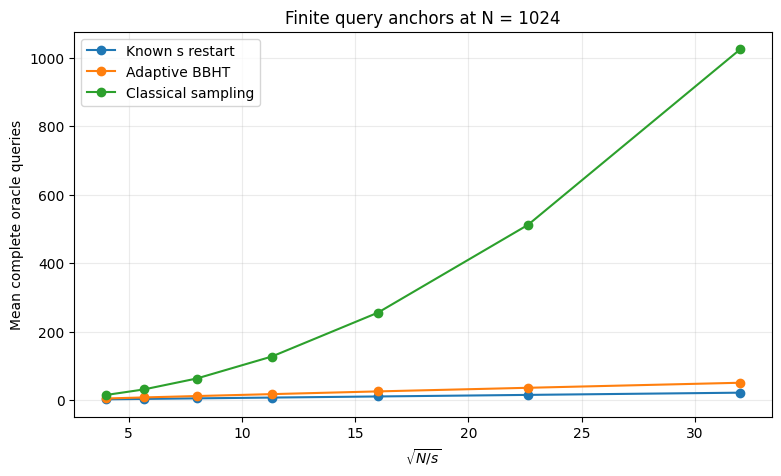

In [10]:
plt.figure(figsize=(9, 5))

plt.plot(
    baseline_comparison_df[
        "sqrt_N_over_s"
    ],
    baseline_comparison_df[
        "known_s_mean_Q"
    ],
    marker="o",
    label="Known s restart",
)

plt.plot(
    baseline_comparison_df[
        "sqrt_N_over_s"
    ],
    baseline_comparison_df[
        "BBHT_mean_Q"
    ],
    marker="o",
    label="Adaptive BBHT",
)

plt.plot(
    baseline_comparison_df[
        "sqrt_N_over_s"
    ],
    baseline_comparison_df[
        "classical_mean_Q"
    ],
    marker="o",
    label="Classical sampling",
)

plt.xlabel(r"$\sqrt{N/s}$")
plt.ylabel("Mean complete oracle queries")
plt.title(
    "Finite query anchors at N = 1024"
)
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 10. Baseline comparison analysis questions

The first completed block should answer only foundation questions.

### 10.1 Is the BBHT implementation truly continuous with Notebook 04?

The deterministic bridge check should reproduce the previous fixed $N$ means.

### 10.2 What is the finite price of not knowing $s$?

Compare adaptive BBHT against the known $s$ restart reference using the same complete phase oracle accounting.

### 10.3 How large is the finite quantum advantage over uniform classical sampling?

Compare the complete mean query costs directly rather than only comparing asymptotic notation.

### 10.4 Does the conclusion change when the $95$th percentile is examined?

A strategy may have a favorable expected cost while still having a substantial runtime tail.

### 10.5 What remains unknown after this block?

Nothing in the baseline comparison yet tells us whether it is better to

$$
\text{adapt},
$$

$$
\text{estimate then search},
$$

or

$$
\text{use a robust fixed point sequence}.
$$

Those are the next experiments.

## 11. Baseline comparison results and interpretation

the baseline comparison establishes the finite comparison baseline against which the new unknown $s$ strategies will be judged.

### 11.1 The BBHT bridge reproduces Notebook 04 exactly

**Expected.**

Notebook 05 uses the same adaptive BBHT procedure, growth factor,

$$
\lambda=\frac65,
$$

number of runs, and deterministic seed schedule as the fixed $N=1024$ experiment in Notebook 04.

Therefore the corresponding finite sample means should agree exactly.

**Observed.**

For every

$$
s\in\{1,2,4,8,16,32,64\},
$$

the Notebook 05 mean complete phase oracle cost is identical to the stored Notebook 04 value.

The maximum absolute discrepancy is

$$
\boxed{0.0}.
$$

**Why?**

The two experiments use the same random process and the same seed for each run. Once the implementation and query accounting are unchanged, the generated trajectories are identical.

**Interpretation.**

Notebook 05 is numerically continuous with Notebook 04. The comparison does not begin from a modified BBHT baseline.

### 11.2 What is the finite price of not knowing $s$?

**Expected.**

The known $s$ restart strategy should be cheaper because it can choose its stopping rule using the true marked count.

Adaptive BBHT must instead spend queries discovering a useful iteration scale through randomized rounds and verification.

**Observed.**

At

$$
N=1024,
$$

the mean complete phase oracle cost for $s=1$ is approximately

$$
22.675
$$

for the known $s$ reference and

$$
51.632
$$

for adaptive BBHT.

The ratio is therefore

$$
\frac{51.632}{22.675}
\approx
2.277.
$$

At $s=64$, the corresponding costs are approximately

$$
3.302
$$

and

$$
5.731,
$$

giving a ratio of approximately

$$
1.735.
$$

Across the tested sweep, the BBHT mean cost is about $1.74$ to $2.28$ times the known $s$ reference.

**Why?**

The known $s$ strategy receives information that BBHT does not have. It can select an effective restart depth immediately.

BBHT pays an uncertainty overhead through unsuccessful rounds, verification queries, and growth of the randomization range.

**Interpretation.**

The comparison quantifies the finite cost of removing exact knowledge of $s$. The overhead is substantial but remains far smaller than abandoning amplitude amplification entirely in the sparse cases tested here.

The ratios are finite instance observations, not universal constants.

### 11.3 How large is the finite advantage over uniform classical sampling?

**Expected.**

Classical uniform sampling has mean query cost

$$
\mathbb E[Q_{\mathrm{classical}}]
=
\frac Ns,
$$

whereas BBHT is expected to operate on a square root search scale.

The separation should therefore be largest when marked states are sparse.

**Observed.**

For

$$
N=1024,
\qquad
s=1,
$$

classical sampling requires

$$
1024
$$

queries on average, while adaptive BBHT requires approximately

$$
51.632.
$$

Thus classical sampling uses approximately

$$
19.83
$$

times as many mean queries.

For

$$
s=64,
$$

the mean costs are

$$
16
$$

for classical sampling and approximately

$$
5.731
$$

for BBHT, giving a ratio of approximately

$$
2.79.
$$

The classical to BBHT mean cost ratio decreases steadily over this tested sweep as the marked fraction grows.

**Why?**

When $s/N$ is small, uniform sampling wastes most queries on unmarked candidates.

Amplitude amplification exploits coherent rotations toward the marked subspace, while adaptive BBHT searches for a useful rotation scale without first knowing $s$.

As the marked fraction becomes larger, a random classical candidate is already more likely to succeed, so the finite advantage of quantum amplification naturally narrows.

**Interpretation.**

For these finite instances, adaptive BBHT retains a clear query advantage over uniform classical sampling, especially in the sparse solution regime.

This is a finite comparison under the common oracle accounting used here. It is not a statement about wall clock runtime or hardware cost.

### 11.4 Does the conclusion change at the $95$th percentile?

**Expected.**

Mean cost alone may hide the variability of adaptive search.

Because BBHT can experience several unsuccessful rounds before success, its upper tail should be more expensive relative to its mean than the tuned known $s$ reference.

Classical uniform sampling also has a long geometric tail.

**Observed.**

For

$$
N=1024,
\qquad
s=1,
$$

the $95$th percentile complete query costs are

$$
38
$$

for the known $s$ reference,

$$
96
$$

for adaptive BBHT, and

$$
3067
$$

for classical uniform sampling.

At

$$
s=64,
$$

the corresponding values are

$$
6,
\qquad
12,
\qquad
47.
$$

Across the tested sweep, the BBHT $95$th percentile is about $2.00$ to $2.54$ times the known $s$ reference.

Relative to its own mean, the BBHT $95$th percentile is about $1.86$ to $2.09$ times the mean, while the classical geometric reference is close to three times its mean.

**Why?**

Adaptive BBHT has trajectory variability. Different runs can fail at different random iteration counts and therefore reach different range sizes before succeeding.

The known $s$ restart reference removes much of that uncertainty by using a tuned depth from the beginning.

The classical strategy has a geometric waiting time, so occasional long runs remain unavoidable even though each individual trial is simple.

**Interpretation.**

The ordering does not reverse when tail behavior is considered.

The known $s$ reference remains cheapest, BBHT remains substantially cheaper than classical sampling, and BBHT pays an additional variability cost for operating without exact knowledge of $s$.

The tail comparison therefore strengthens rather than contradicts the mean cost result.

### 11.5 What the baseline comparison establishes and what it does not

the baseline comparison establishes four things.

First, the adaptive BBHT implementation is exactly continuous with Notebook 04.

Second, exact knowledge of $s$ provides a measurable finite advantage over adaptive search.

Third, adaptive BBHT still gives a large finite query reduction over uniform classical sampling in the tested sparse and moderately sparse instances.

Fourth, the advantage survives a $95$th percentile comparison even though BBHT has a broader runtime distribution than the known $s$ reference.

the baseline comparison does **not** yet answer the main comparative research question.

The unresolved comparison is

$$
\boxed{
\text{adapt}
\quad\text{versus}\quad
\text{estimate then search}
\quad\text{versus}\quad
\text{robust fixed point amplification}.
}
$$

That requires implementing the next strategies under the same query accounting and information assumptions.

With the baseline references, BBHT bridge, mean comparison, and tail comparison now validated and interpreted, the baseline comparison is complete.

## 12. Counting assisted Grover search

The baseline comparison established the comparison baseline.

the counting assisted comparison now introduces the first genuinely new competitor:

$$
\boxed{
\text{estimate }s\text{ first, then choose a Grover restart depth from that estimate.}
}
$$

The implementation is based on the canonical quantum counting procedure of Brassard, Høyer, and Tapp.

For a counting budget $P$, the algorithm estimates the phase

$$
\theta
\quad\text{where}\quad
\sin^2\theta=\frac{s}{N}.
$$

If the measured folded Fourier outcome is $\tilde f$, the corresponding marked count estimate is

$$
\tilde s
=
N\sin^2\left(
\frac{\pi\tilde f}{P}
\right).
$$

In the canonical construction, the controlled Grover stage uses exactly $P$ evaluations of the Boolean oracle.

Therefore those $P$ queries must be charged before any later search queries are counted.

This phase studies a concrete policy:

$$
\text{Count once}
\rightarrow
\text{choose a fixed restart depth from }\tilde s
\rightarrow
\text{verify and restart until success}.
$$

This is one specific counting assisted search strategy, not a claim that every possible use of quantum counting must behave the same way.

### 12.1 Finite counting budget

The quantum counting paper uses an integer parameter $P$ to control both precision and query cost.

For simplicity, the original presentation assumes $P$ is a power of two.

The estimator obeys the finite error guarantee

$$
\left|
s-\tilde s
\right|
<
\frac{2\pi}{P}\sqrt{sN}
+
\frac{\pi^2}{P^2}N
$$

with probability at least

$$
\frac{8}{\pi^2}.
$$

The guarantee does not say that the estimate is always close.

That distinction matters because a rare poor estimate can choose a poor Grover stopping depth and strongly affect the complete search cost.

In [11]:
def validate_count_budget(P):
    if not isinstance(P, (int, np.integer)):
        raise ValueError("P must be an integer")

    if P < 4:
        raise ValueError("P must satisfy P >= 4")

    if P & (P - 1):
        raise ValueError(
            "This experiment uses power of two counting budgets"
        )

    return int(P)


def phase_estimation_kernel(P, phi):
    P = validate_count_budget(P)

    phi = float(phi) % 1.0

    k = np.arange(P, dtype=float)[:, None]
    y = np.arange(P, dtype=float)[None, :]

    phase_difference = phi - y / P

    amplitudes = np.mean(
        np.exp(
            2j
            * np.pi
            * k
            * phase_difference
        ),
        axis=0,
    )

    probabilities = np.abs(amplitudes) ** 2
    probabilities = probabilities / probabilities.sum()

    return probabilities


def quantum_counting_distribution(N, s, P):
    N, s = validate_search_instance(N, s)
    P = validate_count_budget(P)

    if s > N / 2:
        raise ValueError(
            "The canonical counting experiment here uses s <= N/2"
        )

    theta = theta_from_N_s(N, s)
    phi = theta / np.pi

    positive_branch = phase_estimation_kernel(P, phi)
    negative_branch = phase_estimation_kernel(P, -phi)

    raw_probability = (
        0.5 * positive_branch
        + 0.5 * negative_branch
    )

    folded = {}

    for y_value, probability in enumerate(raw_probability):
        f_tilde = min(
            y_value,
            P - y_value,
        )

        folded[f_tilde] = (
            folded.get(f_tilde, 0.0)
            + float(probability)
        )

    rows = []

    for f_tilde in sorted(folded):
        probability = folded[f_tilde]

        s_tilde = (
            N
            * np.sin(
                np.pi
                * f_tilde
                / P
            ) ** 2
        )

        rows.append({
            "f_tilde": int(f_tilde),
            "probability": float(probability),
            "s_tilde": float(s_tilde),
            "absolute_error": float(abs(s_tilde - s)),
        })

    df = pd.DataFrame(rows)

    if not np.isclose(
        df["probability"].sum(),
        1.0,
        atol=1e-12,
    ):
        raise RuntimeError(
            "Quantum counting probabilities do not sum to one"
        )

    return df


print("Quantum counting distribution definitions: PASS")

Quantum counting distribution definitions: PASS


### 12.2 Sanity check: an exactly resolved phase

When

$$
\frac{P\theta}{\pi}
$$

is an integer, the ideal Fourier measurement resolves the counting phase exactly.

A simple test is

$$
N=16,
\qquad
s=8,
\qquad
P=8.
$$

Here

$$
\theta=\frac{\pi}{4},
$$

so

$$
\frac{P\theta}{\pi}=2.
$$

After folding the two conjugate phase outcomes, the counting estimator should return

$$
\tilde s=8
$$

with probability one up to floating point precision.

In [12]:
exact_count_sanity = (
    quantum_counting_distribution(
        N=16,
        s=8,
        P=8,
    )
)

exact_count_sanity

,f_tilde,probability,s_tilde,absolute_error
0,0,7.633970e-32,0.000000,8.000000e+00
1,1,1.789189e-31,2.343146,5.656854e+00
2,2,1.000000e+00,8.000000,1.776357e-15
3,3,2.022226e-31,13.656854,5.656854e+00
4,4,2.279301e-32,16.000000,8.000000e+00


In [13]:
exact_count_probability = float(
    exact_count_sanity.loc[
        np.isclose(
            exact_count_sanity["s_tilde"],
            8.0,
            atol=1e-12,
        ),
        "probability",
    ].sum()
)

print(
    "Exactly resolved counting probability:",
    exact_count_probability,
)

print(
    "Exact phase sanity:",
    "PASS"
    if np.isclose(
        exact_count_probability,
        1.0,
        atol=1e-12,
    )
    else "CHECK",
)

Exactly resolved counting probability: 1.0
Exact phase sanity: PASS


### 12.3 Does the implemented estimator reproduce the theorem guarantee?

The next check uses the same finite instance family as the baseline comparison,

$$
N=1024,
$$

with

$$
s\in
\{1,2,4,8,16,32,64\}.
$$

The counting budgets are chosen without using the true $s$:

$$
P\in
\{4,8,16,32,64,128\}.
$$

Since

$$
\sqrt{1024}=32,
$$

these correspond to fixed budget multipliers

$$
\frac{P}{\sqrt N}
\in
\left\{
\frac18,
\frac14,
\frac12,
1,
2,
4
\right\}.
$$

For every pair $(s,P)$ we calculate the exact probability mass satisfying the theorem error bound and compare it with

$$
\frac{8}{\pi^2}.
$$

In [14]:
def quantum_counting_error_bound(N, s, P):
    N, s = validate_search_instance(N, s)
    P = validate_count_budget(P)

    return float(
        (2 * np.pi / P)
        * sqrt(s * N)
        +
        (np.pi ** 2 / P ** 2)
        * N
    )


P_values = [4, 8, 16, 32, 64, 128]

counting_validation_rows = []

for P in P_values:
    for s in s_bridge:
        distribution = quantum_counting_distribution(
            N_bridge,
            s,
            P,
        )

        bound = quantum_counting_error_bound(
            N_bridge,
            s,
            P,
        )

        probability_inside_bound = float(
            distribution.loc[
                distribution["absolute_error"] < bound,
                "probability",
            ].sum()
        )

        counting_validation_rows.append({
            "N": N_bridge,
            "s": s,
            "P": P,
            "P_over_sqrt_N": P / sqrt(N_bridge),
            "error_bound": bound,
            "probability_inside_bound": probability_inside_bound,
            "required_probability": 8 / np.pi ** 2,
            "bound_reproduced":
                probability_inside_bound + 1e-12
                >= 8 / np.pi ** 2,
        })

counting_validation_df = pd.DataFrame(
    counting_validation_rows
)

counting_validation_df

,N,s,P,P_over_sqrt_N,error_bound,probability_inside_bound,required_probability,bound_reproduced
0,1024,1,4,0.125,681.920164,0.999027,0.810569,True
1,1024,2,4,0.125,702.740809,0.998062,0.810569,True
2,1024,4,4,0.125,732.185647,0.996155,0.810569,True
3,1024,8,4,0.125,773.826936,0.992430,0.810569,True
4,1024,16,4,0.125,832.716611,0.985336,0.810569,True
5,1024,32,4,0.125,915.999190,0.972534,0.810569,True
6,1024,64,4,0.125,1033.778541,1.000000,0.810569,True
7,1024,1,8,0.250,183.046412,0.992956,0.810569,True
8,1024,2,8,0.250,193.456734,0.986161,0.810569,True
9,1024,4,8,0.250,208.179153,0.973305,0.810569,True


In [15]:
counting_bound_pass = bool(
    counting_validation_df[
        "bound_reproduced"
    ].all()
)

print(
    "Quantum counting theorem bound check:",
    "PASS" if counting_bound_pass else "CHECK",
)

print(
    "Minimum observed probability inside bound:",
    float(
        counting_validation_df[
            "probability_inside_bound"
        ].min()
    ),
)

print(
    "Theoretical lower guarantee:",
    float(8 / np.pi ** 2),
)

Quantum counting theorem bound check: PASS
Minimum observed probability inside bound: 0.8330689690473679
Theoretical lower guarantee: 0.8105694691387022


### 12.4 Converting a count estimate into a Grover restart depth

Quantum counting returns a real valued estimate $\tilde s$.

The search stage needs an integer Grover depth.

For a particular estimate, this notebook chooses the integer $t$ that minimizes the assumed complete phase query cost

$$
\frac{t+1}
{\sin^2((2t+1)\tilde\theta)},
$$

where

$$
\tilde\theta
=
\arcsin
\sqrt{
\frac{\tilde s}{N}
}.
$$

The minimization uses the same restart objective as the known $s$ reference in the baseline comparison.

If the finite counting measurement returns $\tilde s=0$, the search problem promise

$$
s\ge1
$$

is used to floor the effective estimate at one marked state.

This prevents an unresolved coarse counting outcome from being interpreted as a proof that no solution exists.

The upper endpoint is similarly kept inside the nontrivial search domain.

In [16]:
def restart_depth_from_count_estimate(
    N,
    s_tilde,
):
    if not isinstance(N, (int, np.integer)):
        raise ValueError("N must be an integer")

    if N < 2:
        raise ValueError("N must satisfy N >= 2")

    if not np.isfinite(s_tilde):
        raise ValueError("s_tilde must be finite")

    effective_s = float(
        np.clip(
            s_tilde,
            1.0,
            N - 1.0,
        )
    )

    theta_tilde = asin(
        sqrt(effective_s / N)
    )

    best_cost = float("inf")
    best_t = 0
    t = 0

    while True:
        p_assumed = (
            sin(
                (2 * t + 1)
                * theta_tilde
            ) ** 2
        )

        assumed_cost = (
            (t + 1) / p_assumed
        )

        if assumed_cost < best_cost:
            best_cost = assumed_cost
            best_t = t

        next_t = t + 1

        if next_t + 1 > best_cost:
            break

        t = next_t

    return int(best_t)


print("Count estimate to restart depth definition: PASS")

Count estimate to restart depth definition: PASS


### 12.5 Complete query accounting for counting assisted search

A complete run consists of two stages.

First, quantum counting spends exactly

$$
P
$$

phase oracle queries.

Second, the measured count estimate determines one fixed Grover restart depth $t$.

Each later search attempt costs

$$
t+1
$$

phase oracle queries:

$$
t
$$

for amplification and one for verification.

The true success probability of that attempt is still determined by the true $s$,

$$
p_{\mathrm{true}}
=
\sin^2((2t+1)\theta).
$$

Conditioned on one counting outcome, the number of search attempts is geometric.

Therefore

$$
\mathbb E[
Q_{\mathrm{total}}
\mid
\tilde s
]
=
P
+
\frac{t+1}
{p_{\mathrm{true}}}.
$$

The unconditional mean averages this quantity over the full quantum counting outcome distribution.

This is important because rare count outcomes can produce a poor stopping depth and can dominate the expected complete cost.

In [17]:
def counting_assisted_components(
    N,
    s,
    P,
):
    N, s = validate_search_instance(N, s)
    P = validate_count_budget(P)

    count_df = quantum_counting_distribution(
        N,
        s,
        P,
    )

    rows = []

    for _, row in count_df.iterrows():
        s_tilde = float(row["s_tilde"])

        t = restart_depth_from_count_estimate(
            N,
            s_tilde,
        )

        p_true = grover_probability(
            N,
            s,
            t,
        )

        attempt_cost = t + 1

        conditional_mean_search = (
            float("inf")
            if p_true <= 0
            else attempt_cost / p_true
        )

        rows.append({
            "f_tilde": int(row["f_tilde"]),
            "count_probability": float(row["probability"]),
            "s_tilde": s_tilde,
            "chosen_t": int(t),
            "true_attempt_success": float(p_true),
            "attempt_phase_cost": int(attempt_cost),
            "conditional_mean_search_queries":
                float(conditional_mean_search),
        })

    return pd.DataFrame(rows)


def counting_assisted_cdf(
    total_queries,
    P,
    components,
):
    total_queries = float(total_queries)
    probability = 0.0

    for _, row in components.iterrows():
        weight = float(row["count_probability"])
        p_true = float(row["true_attempt_success"])
        attempt_cost = int(row["attempt_phase_cost"])

        attempts_possible = int(
            np.floor(
                (total_queries - P)
                / attempt_cost
            )
        )

        if attempts_possible <= 0:
            conditional_cdf = 0.0

        elif p_true <= 0:
            conditional_cdf = 0.0

        elif p_true >= 1.0:
            conditional_cdf = 1.0

        else:
            conditional_cdf = float(
                -np.expm1(
                    attempts_possible
                    * np.log1p(-p_true)
                )
            )

        probability += (
            weight * conditional_cdf
        )

    return float(
        np.clip(
            probability,
            0.0,
            1.0,
        )
    )


def counting_assisted_quantile(
    P,
    components,
    quantile,
):
    if not 0 < quantile < 1:
        raise ValueError(
            "quantile must lie in (0, 1)"
        )

    nonterminating_mass = float(
        components.loc[
            components[
                "true_attempt_success"
            ] <= 0,
            "count_probability",
        ].sum()
    )

    if nonterminating_mass >= 1 - quantile:
        return float("inf")

    low = int(P)
    high = int(P + 1)
    maximum_search = 10 ** 12

    while (
        counting_assisted_cdf(
            high,
            P,
            components,
        )
        < quantile
        and high < maximum_search
    ):
        high = int(
            P + 2 * (high - P)
        )

    if (
        counting_assisted_cdf(
            high,
            P,
            components,
        )
        < quantile
    ):
        return float("inf")

    while low + 1 < high:
        middle = (
            low + high
        ) // 2

        if (
            counting_assisted_cdf(
                middle,
                P,
                components,
            )
            >= quantile
        ):
            high = middle
        else:
            low = middle

    return float(high)


def counting_assisted_summary(
    N,
    s,
    P,
):
    components = counting_assisted_components(
        N,
        s,
        P,
    )

    weighted_search_means = (
        components[
            "count_probability"
        ]
        * components[
            "conditional_mean_search_queries"
        ]
    )

    mean_search = float(
        weighted_search_means.sum()
    )

    mean_total = P + mean_search

    q50 = counting_assisted_quantile(
        P,
        components,
        0.50,
    )

    q90 = counting_assisted_quantile(
        P,
        components,
        0.90,
    )

    q95 = counting_assisted_quantile(
        P,
        components,
        0.95,
    )

    zero_estimate_mass = float(
        components.loc[
            np.isclose(
                components["s_tilde"],
                0.0,
                atol=1e-12,
            ),
            "count_probability",
        ].sum()
    )

    return {
        "N": int(N),
        "s": int(s),
        "P": int(P),
        "P_over_sqrt_N": float(P / sqrt(N)),
        "mean_total_phase_queries": float(mean_total),
        "median_total_phase_queries": float(q50),
        "q90_total_phase_queries": float(q90),
        "q95_total_phase_queries": float(q95),
        "q95_over_mean": float(q95 / mean_total),
        "zero_estimate_probability": zero_estimate_mass,
    }, components


print("Counting assisted complete cost definitions: PASS")

Counting assisted complete cost definitions: PASS


### 12.6 Controlled example: why a finite counting estimate can matter

Consider

$$
N=1024,
\qquad
s=8,
\qquad
P=32.
$$

The table below sorts the counting outcomes by probability.

For each outcome it shows

1. the count estimate,
2. the Grover depth selected from that estimate,
3. the true success probability at that depth,
4. the conditional expected search cost.

This exposes the mechanism connecting estimation error to complete query cost.

In [18]:
controlled_summary, controlled_components = (
    counting_assisted_summary(
        N=1024,
        s=8,
        P=32,
    )
)

controlled_components_sorted = (
    controlled_components
    .sort_values(
        "count_probability",
        ascending=False,
    )
    .reset_index(drop=True)
)

controlled_components_sorted.head(10)

,f_tilde,count_probability,s_tilde,chosen_t,true_attempt_success,attempt_phase_cost,conditional_mean_search_queries
0,1,0.971141,9.837936,6,0.833548,7,8.397838
1,0,0.011594,0.000000,18,0.017598,19,1079.669904
2,2,0.008965,38.973679,3,0.337154,4,11.863998
3,3,0.002813,86.287559,2,0.183370,3,16.360354
4,4,0.001432,149.961328,1,0.068855,2,29.046427
5,5,0.000893,227.548041,1,0.068855,2,29.046427
6,6,0.000624,316.066083,1,0.068855,2,29.046427
7,7,0.000470,412.113755,0,0.007813,1,128.000000
8,8,0.000374,512.000000,0,0.007813,1,128.000000
9,9,0.000310,611.886245,0,0.007813,1,128.000000


In [19]:
pd.DataFrame(
    [controlled_summary]
)

,N,s,P,P_over_sqrt_N,mean_total_phase_queries,median_total_phase_queries,q90_total_phase_queries,q95_total_phase_queries,q95_over_mean,zero_estimate_probability
0,1024,8,32,1.0,53.236174,39.0,46.0,46.0,0.864074,0.011594


## 13. Counting budget sweep

The full the counting assisted comparison experiment evaluates all fixed counting budgets

$$
P\in
\{4,8,16,32,64,128\}
$$

on the baseline search family.

The budget is fixed independently of the true $s$.

This is essential.

Choosing the best $P$ separately for each true $s$ would use the information the strategy is supposed not to know.

For diagnostic purposes we may inspect which budget would have been best after the fact, but that lower envelope must not be presented as a deployable unknown $s$ algorithm.

In [20]:
counting_sweep_rows = []
counting_component_cache = {}

for P in P_values:
    for s in s_bridge:
        summary, components = (
            counting_assisted_summary(
                N=N_bridge,
                s=s,
                P=P,
            )
        )

        counting_component_cache[
            (N_bridge, s, P)
        ] = components

        bbht_row = (
            baseline_comparison_df.loc[
                baseline_comparison_df["s"] == s
            ]
            .iloc[0]
        )

        summary["BBHT_mean_Q"] = float(
            bbht_row["BBHT_mean_Q"]
        )

        summary["BBHT_q95_Q"] = float(
            bbht_row["BBHT_q95_Q"]
        )

        summary[
            "counting_over_BBHT_mean"
        ] = (
            summary[
                "mean_total_phase_queries"
            ]
            / summary["BBHT_mean_Q"]
        )

        summary[
            "counting_over_BBHT_q95"
        ] = (
            summary[
                "q95_total_phase_queries"
            ]
            / summary["BBHT_q95_Q"]
        )

        counting_sweep_rows.append(
            summary
        )

counting_sweep_df = pd.DataFrame(
    counting_sweep_rows
)

counting_sweep_df

,N,s,P,P_over_sqrt_N,mean_total_phase_queries,median_total_phase_queries,q90_total_phase_queries,q95_total_phase_queries,q95_over_mean,zero_estimate_probability,BBHT_mean_Q,BBHT_q95_Q,counting_over_BBHT_mean,counting_over_BBHT_q95
0,1024,1,4,0.125,31.557075,23.0,42.0,42.0,1.330922,0.995125,51.631667,96.0,0.611196,0.437500
1,1024,2,4,0.125,27.878946,23.0,23.0,23.0,0.824995,0.990265,36.922667,71.0,0.755063,0.323944
2,1024,4,4,0.125,43.335117,23.0,80.0,99.0,2.284521,0.980591,26.399000,50.0,1.641544,1.980000
3,1024,8,4,0.125,1046.958165,707.0,2436.0,3177.0,3.034505,0.961424,18.439333,35.0,56.778526,90.771429
4,1024,16,4,0.125,26.528214,23.0,23.0,38.0,1.432437,0.923813,12.836333,25.0,2.066650,1.520000
5,1024,32,4,0.125,203.833463,137.0,479.0,631.0,3.095664,0.851440,8.773000,18.0,23.234180,35.055556
6,1024,64,4,0.125,2398.677038,1220.0,6559.0,8858.0,3.692869,0.717773,5.730667,12.0,418.568585,738.166667
7,1024,1,8,0.250,40.462724,27.0,46.0,46.0,1.136849,0.979652,51.631667,96.0,0.783680,0.479167
8,1024,2,8,0.250,36.430770,27.0,27.0,27.0,0.741132,0.959620,36.922667,71.0,0.986678,0.380282
9,1024,4,8,0.250,50.130007,27.0,84.0,103.0,2.054658,0.920493,26.399000,50.0,1.898936,2.060000


In [21]:
counting_budget_summary_df = (
    counting_sweep_df
    .groupby(
        ["P", "P_over_sqrt_N"],
        as_index=False,
    )
    .agg(
        mean_ratio_to_BBHT=(
            "counting_over_BBHT_mean",
            "mean",
        ),
        median_ratio_to_BBHT=(
            "counting_over_BBHT_mean",
            "median",
        ),
        worst_ratio_to_BBHT=(
            "counting_over_BBHT_mean",
            "max",
        ),
        cases_beating_BBHT_mean=(
            "counting_over_BBHT_mean",
            lambda x: int(
                np.sum(x < 1.0)
            ),
        ),
        maximum_zero_estimate_probability=(
            "zero_estimate_probability",
            "max",
        ),
    )
)

counting_budget_summary_df

,P,P_over_sqrt_N,mean_ratio_to_BBHT,median_ratio_to_BBHT,worst_ratio_to_BBHT,cases_beating_BBHT_mean,maximum_zero_estimate_probability
0,4,0.125,71.950821,2.066650,418.568585,2,0.995125
1,8,0.250,27.268941,2.341868,119.927424,2,0.979652
2,16,0.500,9.362671,2.206605,30.160072,0,0.919669
3,32,1.000,4.851971,2.887099,17.660505,0,0.708221
4,64,2.000,106.062033,4.616340,706.582288,0,0.206644
5,128,4.000,13.367281,8.919280,29.825816,0,0.035837


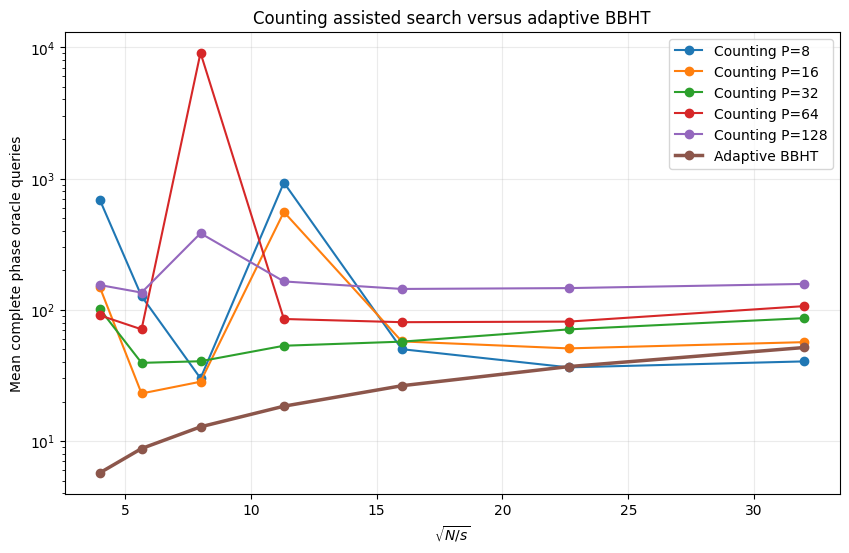

In [22]:
plt.figure(figsize=(10, 6))

for P in [8, 16, 32, 64, 128]:
    subset = (
        counting_sweep_df.loc[
            counting_sweep_df["P"] == P
        ]
        .sort_values("s")
    )

    plt.plot(
        np.sqrt(
            subset["N"]
            / subset["s"]
        ),
        subset[
            "mean_total_phase_queries"
        ],
        marker="o",
        label=f"Counting P={P}",
    )

bbht_plot = (
    baseline_comparison_df
    .sort_values("s")
)

plt.plot(
    bbht_plot["sqrt_N_over_s"],
    bbht_plot["BBHT_mean_Q"],
    marker="o",
    linewidth=2.5,
    label="Adaptive BBHT",
)

plt.yscale("log")
plt.xlabel(r"$\sqrt{N/s}$")
plt.ylabel(
    "Mean complete phase oracle queries"
)
plt.title(
    "Counting assisted search versus adaptive BBHT"
)
plt.legend()
plt.grid(alpha=0.25)
plt.show()

### 13.1 Failure mechanism diagnostics

Two finite mechanisms deserve separate inspection because they explain several large mean costs.

The first occurs when the counting budget is too coarse and a large fraction of the outcome distribution collapses to

$$
\tilde s=0.
$$

The one solution floor then selects a Grover depth appropriate for a very sparse instance, which can be badly mistuned when the true marked count is larger.

The second is more subtle.

Even when the estimator is usually accurate, a low probability outcome can select a Grover depth that lies near a destructive point of the true Grover oscillation.

Such an outcome can contribute little to the median or even the $95$th percentile while dominating the mean.

The following table isolates representative cases.

In [23]:
diagnostic_cases = [
    (8, 4, 0),
    (16, 64, 1),
    (16, 128, 2),
]

diagnostic_rows = []

for s, P, f_tilde in diagnostic_cases:
    components = counting_component_cache[
        (N_bridge, s, P)
    ].copy()

    selected = components.loc[
        components["f_tilde"] == f_tilde
    ].iloc[0]

    weighted_mean_contribution = (
        float(selected["count_probability"])
        * float(
            selected[
                "conditional_mean_search_queries"
            ]
        )
    )

    diagnostic_rows.append({
        "s": s,
        "P": P,
        "f_tilde": f_tilde,
        "count_probability":
            float(selected["count_probability"]),
        "s_tilde":
            float(selected["s_tilde"]),
        "chosen_t":
            int(selected["chosen_t"]),
        "true_attempt_success":
            float(selected["true_attempt_success"]),
        "conditional_mean_search_queries":
            float(
                selected[
                    "conditional_mean_search_queries"
                ]
            ),
        "weighted_mean_contribution":
            weighted_mean_contribution,
    })

counting_failure_diagnostics_df = pd.DataFrame(
    diagnostic_rows
)

counting_failure_diagnostics_df

,s,P,f_tilde,count_probability,s_tilde,chosen_t,true_attempt_success,conditional_mean_search_queries,weighted_mean_contribution
0,8,4,0,0.961424,0.00000,18,0.017598,1079.669904,1038.020421
1,16,64,1,0.048804,2.46542,12,0.000071,184381.883215,8998.566905
2,16,128,2,0.001348,2.46542,12,0.000071,184381.883215,248.635377


## 14. Counting assisted search analysis questions

### 14.1 Does the ideal counting implementation reproduce the finite theorem guarantee?

**Answer: yes, for every tested pair $(s,P)$.**

The theorem check uses

$$
N=1024,
$$

$$
s\in\{1,2,4,8,16,32,64\},
$$

and

$$
P\in\{4,8,16,32,64,128\}.
$$

For each pair, the probability mass satisfying

$$
\left|
s-\tilde s
\right|
<
\frac{2\pi}{P}\sqrt{sN}
+
\frac{\pi^2}{P^2}N
$$

was compared with the theoretical lower guarantee

$$
\frac{8}{\pi^2}
\approx
0.810569.
$$

The smallest observed probability inside the bound was

$$
0.833069,
$$

which remains above the guarantee.

The exactly resolved case

$$
N=16,
\qquad
s=8,
\qquad
P=8
$$

also returned

$$
\tilde s=8
$$

with probability one to floating point precision.

So the estimator itself passes both the exact phase sanity check and the finite theorem check.

The later poor search costs therefore need another explanation. They cannot simply be attributed to an incorrect counting distribution.

### 14.2 What happens when $P$ is too small to resolve the marked count?

**Answer: a large probability mass can collapse to $\tilde s=0$, and the effect of that outcome depends strongly on the true $s$.**

For

$$
P=4,
$$

the maximum zero estimate probability over the tested sweep is approximately

$$
0.995125.
$$

A zero estimate is not automatically catastrophic because the search problem promises

$$
s\ge1.
$$

The implementation therefore floors the effective estimate at one.

If the true problem actually has one marked state, that floor is well matched to the instance.

But when the true marked count is larger, the same outcome can select a badly mistuned Grover depth.

For example,

$$
N=1024,
\qquad
s=8,
\qquad
P=4
$$

returns

$$
\tilde s=0
$$

with probability approximately

$$
0.961424.
$$

After the one solution floor, the selected depth is

$$
t=18.
$$

At the true value $s=8$, this depth has success probability only

$$
0.017598.
$$

Its conditional expected search cost is approximately

$$
1079.67
$$

queries.

Because this poor branch occurs with such high probability, it contributes approximately

$$
1038.02
$$

queries to the unconditional mean by itself.

This explains why the complete mean rises to approximately

$$
1046.96,
$$

while adaptive BBHT requires only about

$$
18.44
$$

mean phase oracle queries on the same instance.

The important point is therefore not merely that coarse counting produces zero estimates.

The problem is the interaction between a coarse estimate and the Grover depth chosen from it.

### 14.3 Does increasing the counting budget always improve complete search cost?

**Answer: no. The total cost is strongly nonmonotonic.**

A larger $P$ improves phase resolution, but it also adds $P$ oracle queries before search begins.

More importantly, changing $P$ changes the discrete counting outcomes and therefore the Grover depths that can be selected.

For

$$
N=1024,
\qquad
s=16,
$$

the mean complete costs for

$$
P=4,8,16,32,64,128
$$

are approximately

$$
26.53,\ 30.06,\ 28.32,\ 40.57,\ 9069.93,\ 382.85.
$$

So

$$
P=64
$$

is dramatically worse than both smaller and larger budgets.

The cause is visible in the outcome distribution.

At

$$
P=64,
$$

the counting outcome

$$
\tilde f=1
$$

occurs with probability approximately

$$
0.048804.
$$

It corresponds to

$$
\tilde s\approx2.465
$$

and selects

$$
t=12.
$$

For the true value

$$
s=16,
$$

that stopping depth has success probability only about

$$
0.000071.
$$

Its conditional expected search cost is approximately

$$
184381.88.
$$

After weighting by its probability, this one branch contributes approximately

$$
8998.57
$$

queries to the overall mean.

At

$$
P=128,
$$

a related destructive outcome has probability only about

$$
0.001348,
$$

but still contributes roughly

$$
248.64
$$

queries to the mean.

Increasing estimation precision therefore does not imply monotonically improving complete search performance.

The nonlinear map

$$
\tilde s
\longrightarrow
t
\longrightarrow
P_{\mathrm{success}}(s,t)
$$

can amplify a relatively small estimation error into a very poor search decision.

### 14.4 Can a fixed counting budget outperform adaptive BBHT?

**Answer: yes on some individual instances, but no tested fixed budget is robust across the full unknown $s$ sweep.**

For

$$
P=4,
$$

counting assisted search beats BBHT in mean cost at

$$
s=1
$$

and

$$
s=2.
$$

The corresponding counting to BBHT mean cost ratios are approximately

$$
0.611
$$

and

$$
0.755.
$$

For

$$
P=8,
$$

it again beats BBHT at

$$
s=1
$$

with ratio approximately

$$
0.784,
$$

and is nearly equal at

$$
s=2
$$

with ratio approximately

$$
0.987.
$$

But the same budgets perform very poorly elsewhere.

For

$$
P=4,
$$

the worst tested ratio to BBHT is approximately

$$
418.57.
$$

For

$$
P=8,
$$

the worst tested ratio is approximately

$$
119.93.
$$

The larger budgets

$$
P\in\{16,32,64,128\}
$$

do not beat BBHT in mean cost for any tested value of $s$.

So counting assisted search can be better when the fixed budget happens to suit the instance, but none of the tested fixed choices gives the broad finite robustness of adaptive BBHT when $s$ is unknown.

### 14.5 Do mean and tail behavior tell the same story?

**Answer: no. They can disagree sharply.**

The clearest case is

$$
N=1024,
\qquad
s=16,
\qquad
P=64.
$$

The mean complete cost is approximately

$$
9069.93,
$$

while the $95$th percentile is only

$$
214.
$$

Thus

$$
Q_{0.95}
<
\mathbb E[Q].
$$

This is not a contradiction.

The destructive outcome discussed above occurs with probability approximately

$$
0.048804,
$$

slightly below five percent.

Most runs therefore avoid that branch, so it has limited influence on the $95$th percentile.

The mean, however, weights every branch by both its probability and its conditional expected cost.

A branch with probability below five percent can therefore dominate the expectation if its conditional restart cost is enormous.

For this strategy, the mean detects rare catastrophic behavior that central quantiles can largely miss.

Therefore both expectation and distributional summaries are necessary.

### 14.6 Is the best counting budget for each $s$ a fair unknown $s$ strategy?

**Answer: no. It is useful only as a diagnostic hindsight lower envelope.**

Among the tested budgets, the mean cost minimizing values are

| true $s$ | best tested $P$ | mean complete phase queries | ratio to BBHT |
| ---: | ---: | ---: | ---: |
| 1 | 4 | 31.557 | 0.611 |
| 2 | 4 | 27.879 | 0.755 |
| 4 | 4 | 43.335 | 1.642 |
| 8 | 32 | 53.236 | 2.887 |
| 16 | 4 | 26.528 | 2.067 |
| 32 | 16 | 23.045 | 2.627 |
| 64 | 64 | 90.684 | 15.824 |

The preferred budget changes with the true marked count.

Choosing these values before running the algorithm would therefore require information about the very quantity the method is supposed to handle without knowing.

Even this hindsight lower envelope beats adaptive BBHT only for

$$
s=1
$$

and

$$
s=2.
$$

It should therefore not be presented as the performance of a deployable unknown $s$ strategy.

Instead, it shows that the choice of counting budget introduces another scale selection problem.

### 14.7 What should happen next?

**Answer: the current count once strategy is not sufficiently robust to serve as the final alternative to adaptive BBHT. The next main comparison should be fixed point quantum search.**

The experiment has identified a concrete failure mechanism:

$$
\boxed{
\text{counting error}
\longrightarrow
\text{mistuned Grover depth}
\longrightarrow
\text{low true success probability}
\longrightarrow
\text{large restart cost}.
}
$$

This does not show that quantum counting or amplitude estimation is intrinsically unsuitable for unknown $s$ search.

It shows that the particular policy studied here,

$$
\text{count once}
\longrightarrow
\text{choose one restart depth}
\longrightarrow
\text{repeat that depth},
$$

can be brittle on finite instances.

A more adaptive estimate and search policy could be investigated later as an extension.

For the present comparison, the next strategy should be fixed point quantum search because it attacks the stopping sensitivity from a different direction: rather than first estimating $s$, it changes the amplification sequence to reduce dependence on a precise stopping point.

## 15. Counting assisted search results and interpretation

The counting assisted experiment produces two distinct findings.

First, the **counting estimator itself behaves as expected**. The exactly resolved sanity check succeeds, and every tested finite instance reproduces the stated quantum counting error guarantee.

Second, **a valid estimator does not guarantee a robust search policy**.

The difficulty appears when the estimated marked count is converted into one deterministic Grover restart depth. Because Grover success is periodic in the iteration count, some finite estimation errors select depths with extremely small true success probability.

This creates two observed failure modes.

For coarse budgets, a large zero estimate probability can cause the one solution floor to select a depth appropriate for a much sparser problem than the true instance.

For finer budgets, even a low probability estimate can occasionally select a nearly destructive Grover depth. Such branches can contribute disproportionately to the expected complete cost.

The result explains why the complete cost is not monotonic in the counting budget and why mean and tail statistics can disagree substantially.

Across the tested family,

$$
N=1024,
\qquad
s\in\{1,2,4,8,16,32,64\},
$$

no single fixed counting budget

$$
P\in\{4,8,16,32,64,128\}
$$

provides robust mean query performance relative to adaptive BBHT.

Small budgets can outperform BBHT on the sparsest tested instances, but they can fail dramatically elsewhere. Larger budgets pay greater estimation cost and can still retain rare destructive branches.

The finite evidence therefore supports the following conclusion for the specific strategy tested here:

$$
\boxed{
\text{estimating }s\text{ once and committing to one restart depth is not robust across the tested unknown }s\text{ regime}.
}
$$

This conclusion is deliberately limited.

It does not rule out more adaptive uses of quantum counting or amplitude estimation.

It shows why any such method must be evaluated by its **complete estimate to decision to search pipeline**, rather than by estimation accuracy alone.

The comparison now motivates the next question:

$$
\boxed{
\text{Can fixed point quantum search trade some peak efficiency for greater robustness to uncertainty in the marked fraction?}
}
$$

## 16. Next comparison

The next strategy will be fixed point quantum search.

The comparison must first specify exactly which fixed point construction is being tested and what prior information it receives.

In particular, its stopping rule should not be given the true value of $s$ unless that information is explicitly counted as an oracle informed reference.

The next implementation will therefore begin by fixing

1. the fixed point construction,
2. its prior bound assumptions,
3. its target failure tolerance,
4. its oracle query accounting,
5. the finite instance regime in which the comparison is meaningful.

Only after those assumptions are explicit will the method be placed beside adaptive BBHT and counting assisted search.

## References

1. Michel Boyer, Gilles Brassard, Peter Høyer, and Alain Tapp, *Tight bounds on quantum searching*.
2. Gilles Brassard, Peter Høyer, and Alain Tapp, *Quantum Counting*.
3. Gilles Brassard, Peter Høyer, Michele Mosca, and Alain Tapp, *Quantum Amplitude Amplification and Estimation*.
4. Theodore J. Yoder, Guang Hao Low, and Isaac L. Chuang, *Fixed point quantum search with an optimal number of queries*.
5. Lov K. Grover, Apoorva Patel, and Tathagat Tulsi, *Quantum Algorithms with Fixed Points: The Case of Database Search*.